# Assignment: Mountain Car under 200 steps

Reuse the exact [CartPole learner](../qlearning.py), changing the environment,
bins, and training budget. Mountain Car has two observations (position and
velocity), three actions, and a sparse success condition. The maintained
[Gymnasium environment](https://gymnasium.farama.org/environments/classic_control/mountain_car/)
supplies the actual reward and termination values used here.

In [1]:
import os
os.environ['PYGAME_HIDE_SUPPORT_PROMPT']='1'
os.environ['SDL_VIDEODRIVER']='dummy'
import sys
sys.path.insert(0,'..')
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
import gymnasium as gym
from qlearning import discretize,train_gym,evaluate_gym

In [2]:
environment='MountainCar-v0'
bounds=((-1.2,0.6),(-0.07,0.07))
bins=(30,30)
assert discretize([-1.2,-0.07],bounds,bins)==(0,0)
assert discretize([0.6,0.07],bounds,bins)==(29,29)
q_final,q_best,returns,checkpoints=train_gym(environment,bounds,bins,16000,42,0.15,0.99,1000)
assert not np.shares_memory(q_final,q_best)
pd.DataFrame(checkpoints).to_csv('mountaincar-validation.csv',index=False)
np.savez_compressed('mountaincar-policy.npz',final=q_final,best=q_best,returns=returns)

MountainCar-v0 {'episode': 1000, 'validation_return': -200.0, 'training_mean_100': -200.0}


MountainCar-v0 {'episode': 2000, 'validation_return': -200.0, 'training_mean_100': -200.0}


MountainCar-v0 {'episode': 3000, 'validation_return': -200.0, 'training_mean_100': -200.0}


MountainCar-v0 {'episode': 4000, 'validation_return': -200.0, 'training_mean_100': -200.0}


MountainCar-v0 {'episode': 5000, 'validation_return': -200.0, 'training_mean_100': -200.0}


...

MountainCar-v0 {'episode': 12000, 'validation_return': -157.4, 'training_mean_100': -176.46}


MountainCar-v0 {'episode': 13000, 'validation_return': -178.36, 'training_mean_100': -176.59}


MountainCar-v0 {'episode': 14000, 'validation_return': -176.76, 'training_mean_100': -167.09}


MountainCar-v0 {'episode': 15000, 'validation_return': -133.48, 'training_mean_100': -138.15}


MountainCar-v0 {'episode': 16000, 'validation_return': -186.16, 'training_mean_100': -163.85}


,mean_return,mean_steps,successes_under_200,max_steps
policy,,,,
Best greedy,-140.44,140.44,100,162
Final greedy,-178.78,178.78,57,200
Random,-200.00,200.00,0,200


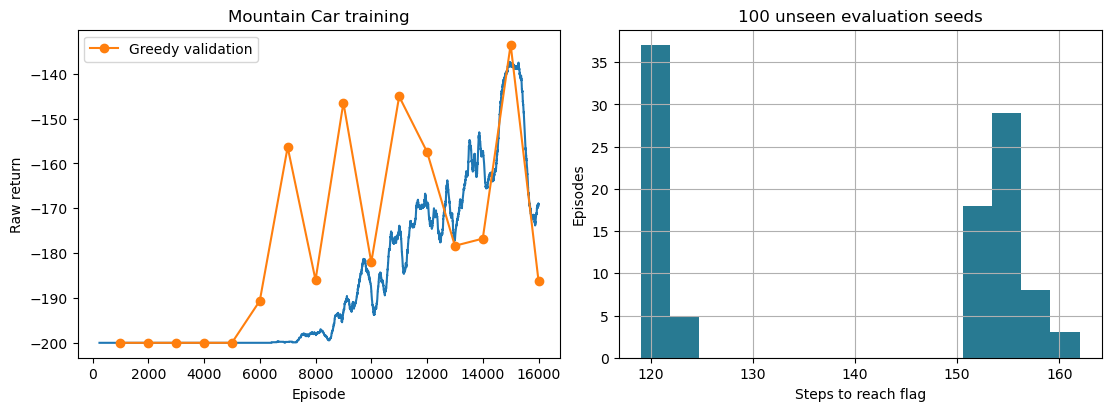

In [3]:
frames=[]
for name,table,policy in [('Random',q_best,'random'),('Final greedy',q_final,'greedy'),('Best greedy',q_best,'greedy')]:
    results=pd.DataFrame(evaluate_gym(environment,table,bounds,bins,range(200000,200100),policy))
    results['policy']=name
    frames.append(results)
results=pd.concat(frames,ignore_index=True)
results['success_under_200']=results.terminated & results.steps.lt(200) & results.final_position.ge(0.5)
summary=results.groupby('policy').agg(mean_return=('return','mean'),mean_steps=('steps','mean'),
                                      successes_under_200=('success_under_200','sum'),max_steps=('steps','max'))
display(summary)
best=results.loc[results.policy.eq('Best greedy')]
assert best.success_under_200.all()
assert best.steps.mean()<200
results.to_csv('mountaincar-test-episodes.csv',index=False)
summary.to_csv('mountaincar-results.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
pd.Series(returns).rolling(250,min_periods=250).mean().plot(ax=axes[0])
validation=pd.DataFrame(checkpoints)
axes[0].plot(validation.episode,validation.validation_return,marker='o',label='Greedy validation')
axes[0].set(title='Mountain Car training',xlabel='Episode',ylabel='Raw return')
axes[0].legend()
best.steps.hist(ax=axes[1],bins=15,color='#287a92')
axes[1].set(title='100 unseen evaluation seeds',xlabel='Steps to reach flag',ylabel='Episodes')
fig.savefig('mountaincar-training.png',dpi=150)
plt.show()

In [4]:
with warnings.catch_warnings():
    warnings.filterwarnings('ignore',message='pkg_resources is deprecated as an API.*',category=UserWarning)
    env=gym.make(environment,max_episode_steps=200,render_mode='rgb_array')
    observation,_=env.reset(seed=200000)
    images=[]
    for count in range(200):
        if count%3==0: images.append(Image.fromarray(env.render()))
        action=int(np.argmax(q_best[discretize(observation,bounds,bins)]))
        observation,reward,terminated,truncated,_=env.step(action)
        if terminated or truncated: break
    env.close()
images[0].save('mountaincar.gif',save_all=True,append_images=images[1:],duration=60,loop=0)
print('Rendered demonstration steps:',count+1,'Reached goal:',terminated)
assert terminated and count+1<200

Rendered demonstration steps: 158 Reached goal: True


## Findings and limits

The best validation checkpoint is selected before the 100 disjoint test
seeds are evaluated. The results include the random and final-table
baselines, so a late training decline remains visible. Learning uses the
environment's raw rewards with no hand-coded momentum controller or
success shaping. The larger training budget and two-dimensional 30×30
discretization adapt the same algorithm to the new state space.

The current environment gives -1 on each transition, including the
successful transition, whereas the historical assignment describes a
different final reward. Counted steps and the actual termination flag
define success here. Passing this finite set of seeds is an empirical
result, not a proof for every possible start or altered physical dynamics.